# Seaborn — the charts you actually use

Seaborn is built on matplotlib. You still get a page and a chart, but you name the columns and seaborn groups the rows for you: counts, averages, spreads, and trend lines.

These charts use a larger class list, `data/college_results.csv`. There are **500 students**. A group this size is big enough for a shape, a trend, and a confidence band to mean something.

| Column | What it holds |
| --- | --- |
| student_id | S001 to S500 |
| department | Computer Science, Mathematics, Physics, Biology, or Commerce |
| year | 1, 2, or 3 |
| hours_studied | hours studied in a typical week |
| attendance | attendance percent |
| sleep_hours | hours of sleep on a typical night |
| assignments | average assignment score |
| exam_score | exam score out of 100 |

Most charts below pass `data=`, then `x` and `y` as column names. `hue` colors the marks by a third column.

Run the cells from the top. Later parts use `students` and `dept_order`.


## Part 1 — Load the class list

`set_theme` turns on the light guide lines behind every chart in this notebook.

`dept_order` lists the departments from the lower average exam score to the higher one. The category charts use that same order, so you can compare them.


In [1]:
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# This seaborn build prints library warnings on the current pandas. Hide them.
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=PendingDeprecationWarning)

sns.set_theme(style="whitegrid")

students = pd.read_csv("data/college_results.csv")

# Low average on the left, high average on the right.
dept_order = (
    students.groupby("department")["exam_score"].mean().sort_values().index.tolist()
)

print(students.shape)  # 500 students, 8 columns
print(dept_order)


(500, 8)
['Commerce', 'Biology', 'Physics', 'Mathematics', 'Computer Science']


## Part 2 — Count plot

A count plot answers: **how many rows fall in each group?** The height of a bar is the number of students. No average is calculated.

On this file, Computer Science is the largest group and Commerce is the smallest. The departments are ordered by average score, the same order as the later charts, so this picture is about headcount along that order.


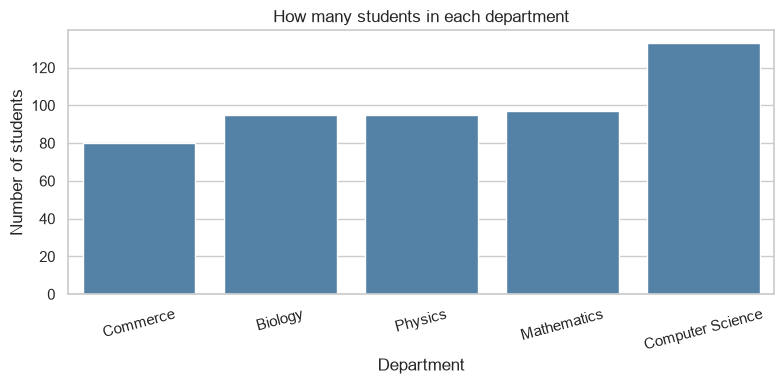

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(data=students, x="department", order=dept_order, color="steelblue", ax=ax)
ax.set_title("How many students in each department")
ax.set_xlabel("Department")
ax.set_ylabel("Number of students")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()


## Part 3 — Histogram

A histogram shows the shape of one number. Each bar is a range of exam scores, and the height is how many students fell in that range.

Here the bars are 5 marks wide. The pile is around the low 60s: most students scored near the middle, with a thin tail of low scores and a thin tail of high scores.


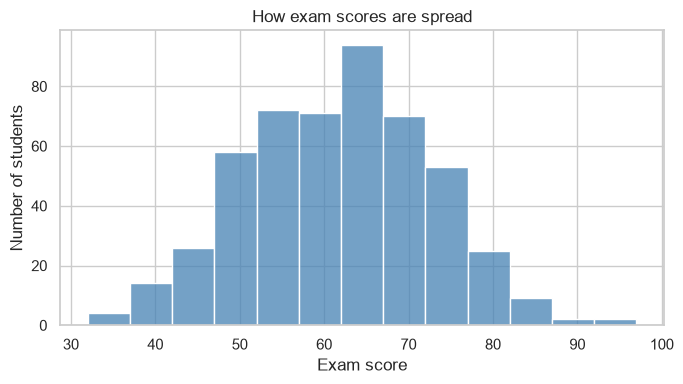

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=students, x="exam_score", binwidth=5, color="steelblue", ax=ax)
ax.set_title("How exam scores are spread")
ax.set_xlabel("Exam score")
ax.set_ylabel("Number of students")
fig.tight_layout()
plt.show()


## Part 4 — Density curve

A density curve is a smooth histogram. The bump is where scores are common. A flat stretch is where scores are rare.

`hue` draws one curve per department. `common_norm=False` scales each department on its own, so the larger Computer Science group does not automatically get a taller curve.

Computer Science sits a little to the right. Commerce sits a little to the left. The curves overlap: the departments differ in the center, and plenty of students in every department share the same scores.


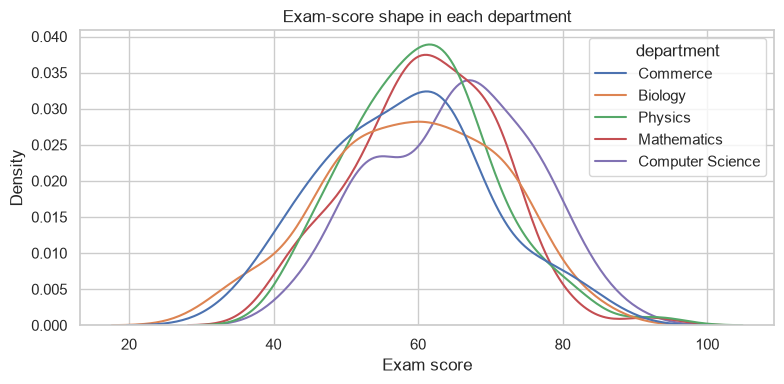

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.kdeplot(
    data=students,
    x="exam_score",
    hue="department",
    hue_order=dept_order,
    common_norm=False,                              # each department scaled on its own
    ax=ax,
)
ax.set_title("Exam-score shape in each department")
ax.set_xlabel("Exam score")
ax.set_ylabel("Density")
fig.tight_layout()
plt.show()


## Part 5 — Box plot

A box plot summarizes the spread inside each group.

- The line inside the box is the **median**, the middle score.
- The box holds the middle half of the students.
- The whiskers reach toward the low and high scores.
- Dots past the whiskers are students who sit far from the rest of their department.

Computer Science's box sits higher. The boxes still overlap, so knowing the department does not tell you a student's exact score.


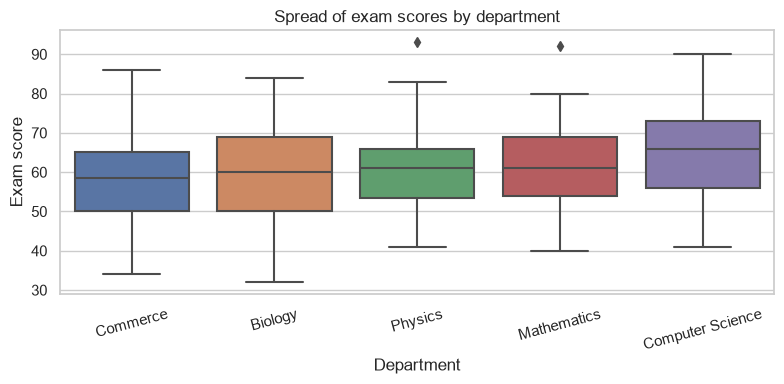

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=students, x="department", y="exam_score", order=dept_order, ax=ax)
ax.set_title("Spread of exam scores by department")
ax.set_xlabel("Department")
ax.set_ylabel("Exam score")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()


## Part 6 — Violin plot

A violin plot shows the same groups as the box plot, plus the full shape. The wider the violin, the more students scored at that height.

`inner="box"` draws a small box inside the violin, so you can see the median and the middle half from Part 5 sitting inside the shape. `cut=0` stops the violin at the lowest and highest real scores.


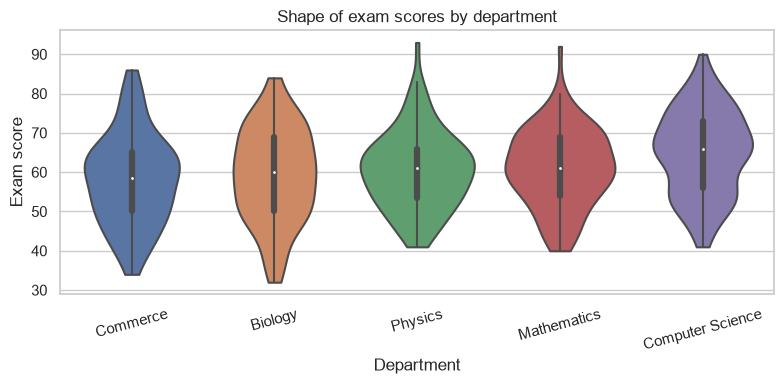

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.violinplot(
    data=students,
    x="department",
    y="exam_score",
    order=dept_order,
    inner="box",                                    # mini box plot inside the shape
    cut=0,                                          # stop at the real min and max
    ax=ax,
)
ax.set_title("Shape of exam scores by department")
ax.set_xlabel("Department")
ax.set_ylabel("Exam score")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()


## Part 7 — Bar plot of the average

This bar plot answers: **what is the average exam score in each department?** The height of the bar is the mean.

The black cap on each bar is a **95% confidence interval** for that mean. It is the uncertainty of the average, not the spread of individual students (that spread was the box plot). Where two caps overlap, the averages are too close to call a clear gap.

The bars start at 0, so the gap is a few marks on a score out of 100. Computer Science is still the high bar. Commerce is the low bar. The caps on Biology, Physics, and Mathematics overlap.


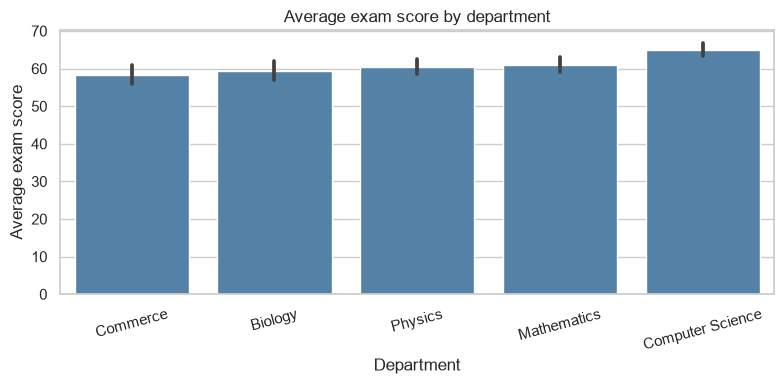

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=students,
    x="department",
    y="exam_score",
    order=dept_order,
    errorbar=("ci", 95),                           # cap = uncertainty of the mean
    color="steelblue",
    ax=ax,
)
ax.set_title("Average exam score by department")
ax.set_xlabel("Department")
ax.set_ylabel("Average exam score")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()


## Part 8 — Scatter plot

A scatter plot draws one dot per student so two numbers can be seen together.

Horizontal position is hours studied in a week. Vertical position is the exam score. Color is the department.

The cloud rises: students who studied more hours tend to score higher. The colors are mixed through the cloud, so department shifts the score a little, while study hours shift it more. The relationship is a cloud, not a perfect line.


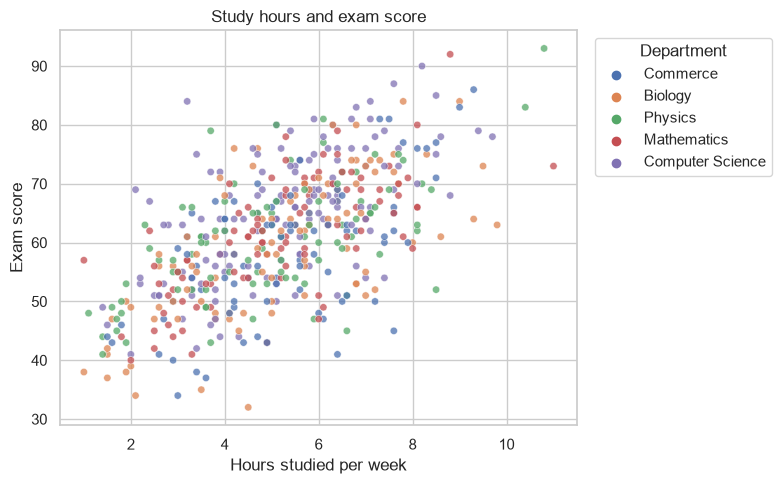

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(
    data=students,
    x="hours_studied",
    y="exam_score",
    hue="department",
    hue_order=dept_order,
    alpha=0.75,                                     # overlap stays visible
    s=28,
    ax=ax,
)
ax.set_title("Study hours and exam score")
ax.set_xlabel("Hours studied per week")
ax.set_ylabel("Exam score")
ax.legend(title="Department", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


## Part 9 — Line plot

A line plot connects an average from left to right. Seaborn computes the average at each x and draws a band around it.

Each dot here is the **mean exam score** of students who studied about that many hours. The band is the 95% confidence interval of that mean. A wide band means the average is less certain, usually because fewer students landed on that hour.

Hours 1 and 9–11 have only a handful of students, so those averages would jump around. This chart keeps hours 2 through 8. Across that range the average rises from the high 40s to about 70.


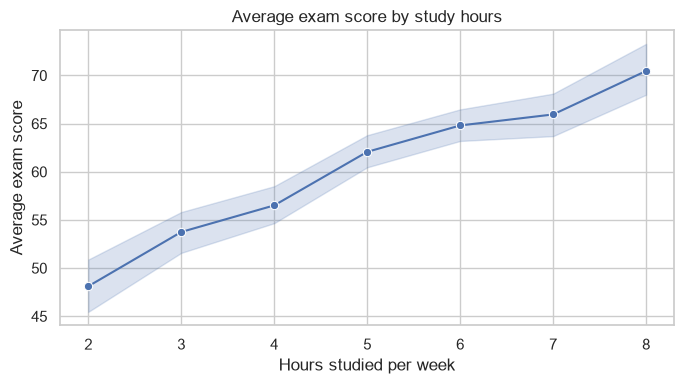

In [9]:
hour_band = students.copy()
hour_band["study_hours"] = hour_band["hours_studied"].round().astype(int)
hour_band = hour_band[hour_band["study_hours"].between(2, 8)]  # enough students at each hour

fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(
    data=hour_band,
    x="study_hours",
    y="exam_score",
    errorbar=("ci", 95),                           # band around the mean
    marker="o",
    ax=ax,
)
ax.set_title("Average exam score by study hours")
ax.set_xlabel("Hours studied per week")
ax.set_ylabel("Average exam score")
fig.tight_layout()
plt.show()


## Part 10 — Scatter with a trend line

`regplot` draws the same cloud as the scatter plot and lays a straight line through it. The line is the single best summary of the upward trend. The pale band around the line is the uncertainty of the line itself.

Dots sit both above and below the line. Study hours and exam score move together, and plenty of students still land off the line.


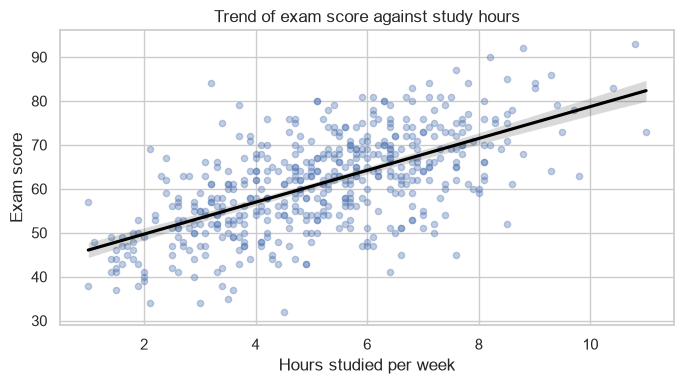

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(
    data=students,
    x="hours_studied",
    y="exam_score",
    scatter_kws={"alpha": 0.35, "s": 20},          # the dots
    line_kws={"color": "black"},                   # the trend line
    ax=ax,
)
ax.set_title("Trend of exam score against study hours")
ax.set_xlabel("Hours studied per week")
ax.set_ylabel("Exam score")
fig.tight_layout()
plt.show()


## Part 11 — Correlation heatmap

A heatmap turns a table of numbers into color. This one is the **correlation** of the numeric columns. Correlation runs from −1 to +1.

- **1.00** on the diagonal is a column compared with itself.
- A positive number means the two columns rise together.
- A negative number means one rises while the other falls.

Exam score moves most with hours studied (about 0.62), then assignment score, then attendance. Sleep is weakly negative: in this file it barely moves with the exam score.


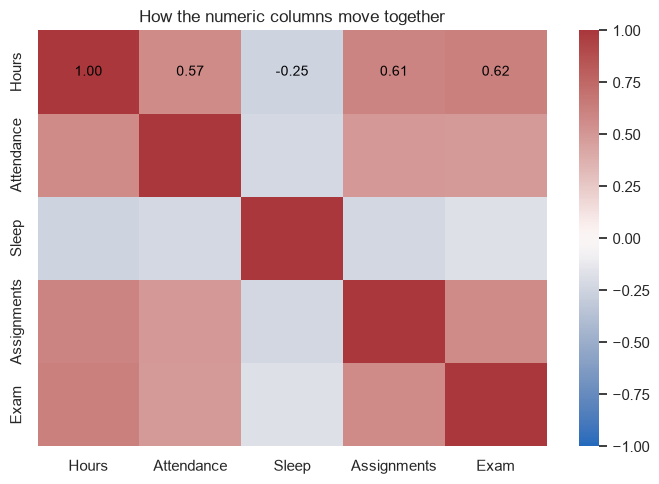

In [11]:
cols = ["hours_studied", "attendance", "sleep_hours", "assignments", "exam_score"]
labels = ["Hours", "Attendance", "Sleep", "Assignments", "Exam"]

corr = students[cols].corr()
corr.index = labels
corr.columns = labels

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    corr,
    cmap="vlag",                                    # blue = positive, red = negative
    center=0,
    vmin=-1,
    vmax=1,
    ax=ax,
)
# Write the correlation in the middle of each cell.
for row in range(len(labels)):
    for col in range(len(labels)):
        ax.text(
            col + 0.5,
            row + 0.5,
            f"{corr.to_numpy()[row, col]:.2f}",
            ha="center",
            va="center",
            fontsize=10,
        )
ax.set_title("How the numeric columns move together")
fig.tight_layout()
plt.show()


## Part 12 — Joint plot

A joint plot is a scatter plot with the spread of each axis attached.

- The center is one dot per student: hours studied against exam score.
- The strip on top is the histogram of study hours.
- The strip on the right is the histogram of exam scores.

You see the relationship and both shapes in one picture. Study hours pile up around 4–6 a week. Exam scores pile up around the low 60s. The cloud in the middle rises.


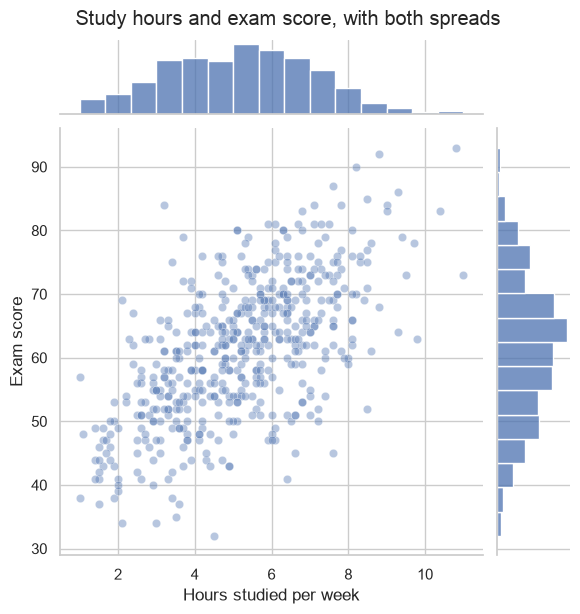

In [12]:
g = sns.jointplot(
    data=students,
    x="hours_studied",
    y="exam_score",
    kind="scatter",
    alpha=0.4,
    height=6,
)
g.fig.suptitle("Study hours and exam score, with both spreads", y=1.02)
g.set_axis_labels("Hours studied per week", "Exam score")
plt.show()


## Part 13 — The same chart, split by year

`relplot` draws one chart per level of a column. `col="year"` makes three panels: year 1, year 2, and year 3.

Each panel is the study-hours scatter. The upward cloud appears in every year, so the relationship is not limited to one batch. Year 3's cloud sits a little higher than year 1 and year 2.


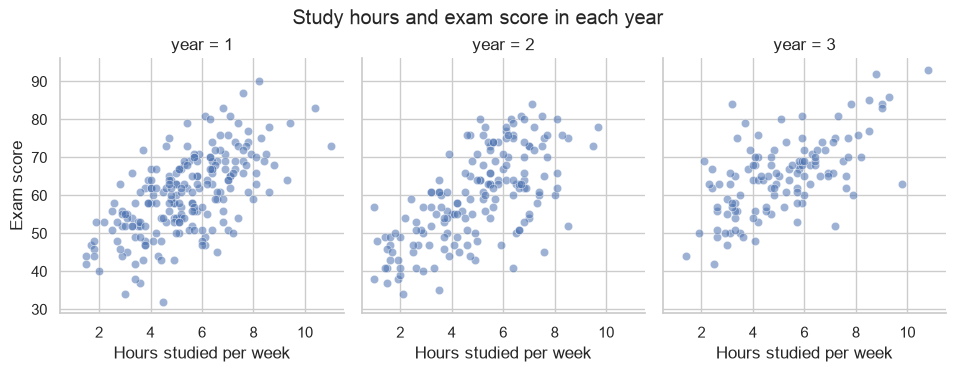

In [13]:
g = sns.relplot(
    data=students,
    x="hours_studied",
    y="exam_score",
    col="year",                                    # one panel per year
    kind="scatter",
    alpha=0.55,
    height=3.6,
    aspect=0.9,
)
g.set_axis_labels("Hours studied per week", "Exam score")
g.fig.suptitle("Study hours and exam score in each year", y=1.03)
plt.show()


## Part 14 — Every pair at once

A pair plot is a grid of the numeric columns.

- The diagonal is the histogram of that column.
- Each off-diagonal panel is the scatter of one column against another.
- `corner=True` keeps the lower triangle, because the upper triangle would repeat the same pairs.

Read a panel by its row and column names. The column against exam score rises for hours studied, attendance, and assignments. That matches the heatmap, drawn as the actual dots.


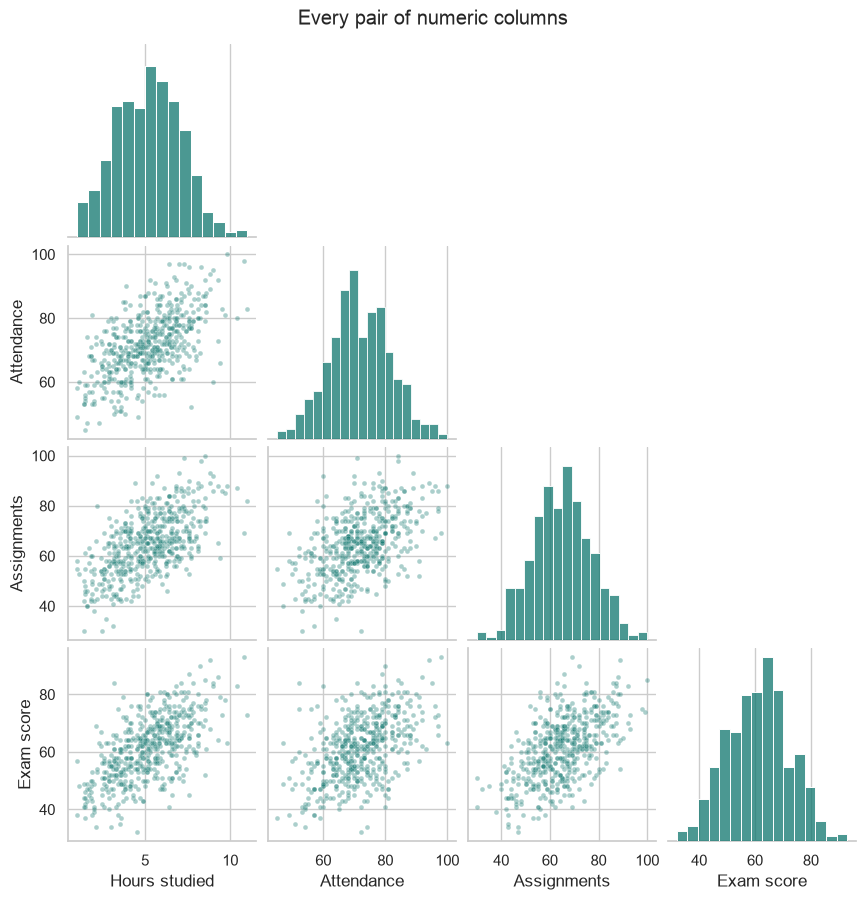

In [19]:
from seaborn import color_palette


paired = students.rename(columns={
    "hours_studied": "Hours studied",
    "attendance": "Attendance",
    "assignments": "Assignments",
    "exam_score": "Exam score",
})
g = sns.pairplot(
    paired,
    vars=["Hours studied", "Attendance", "Assignments", "Exam score"],
    corner=True,                                    # lower triangle only
    diag_kind="hist",
    diag_kws={"color": "#0f766e"},               # histogram bars
    plot_kws={"color": "#0f766e", "alpha": 0.35, "s": 12},  # scatter dots
    height=2.2,
)
g.fig.suptitle("Every pair of numeric columns", y=1.02)
plt.show()


## Part 15 — Save a chart

`savefig` writes the page to an image. Running this cell creates `figures/exam_score_by_department.png`. The chart is the average-score bar plot from Part 7.


In [ ]:
from pathlib import Path

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    data=students,
    x="department",
    y="exam_score",
    order=dept_order,
    errorbar=("ci", 95),
    color="steelblue",
    ax=ax,
)
ax.set_title("Average exam score by department")
ax.set_xlabel("Department")
ax.set_ylabel("Average exam score")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/exam_score_by_department.png", dpi=150, bbox_inches="tight")
plt.show()


## Which chart to reach for

| You want to show… | Use |
| --- | --- |
| How many rows in each group | `countplot` |
| The shape of one number | `histplot` |
| A smooth shape, one curve per group | `kdeplot` |
| Median and spread inside each group | `boxplot` |
| The full shape inside each group | `violinplot` |
| The average of each group, with a confidence cap | `barplot` |
| One dot per row | `scatterplot` |
| The average along an ordered axis, with a band | `lineplot` |
| A straight line through a cloud of dots | `regplot` |
| Correlations as a colored table | `heatmap` on `.corr()` |
| A scatter plus the histogram of each axis | `jointplot` |
| The same chart split into panels | `relplot` with `col=` |
| Every pair of numeric columns | `pairplot` |
| A file for slides | `fig.savefig` |


## Part 16 — A scatter plot from random points

The charts above use the class list. This one starts from nothing: NumPy draws random points, and seaborn paints them.

Each dot is one made-up star on a spiral arm.

- **Color** is the arm, and it deepens as the arm moves outward.
- **Size** is how bright that star is. Stars near the center are larger.
- **Position** is where the point landed after a little random wobble.

The three arms stay separate, so the eye can follow each color all the way around.

In [ ]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

rng = np.random.default_rng(11)


def spiral_arm(phase, name, n=1600, turns=2.15):
    """One arm: an even spiral, then a small random wobble on each point."""
    theta = np.linspace(0.35, turns * 2 * np.pi, n)
    theta = theta + rng.normal(0, 0.045, n)
    radius = 0.42 * (theta - 0.2)
    radius = radius + rng.normal(0, 0.055 + 0.012 * (theta / (2 * np.pi)), n)
    radius = np.clip(radius, 0.05, None)
    return pd.DataFrame(
        {
            "Across": radius * np.cos(theta + phase),
            "Up": radius * np.sin(theta + phase),
            "Distance": radius,
            "Arm": name,
            "Glow": np.clip(90 - radius * 14 + rng.normal(0, 8, n), 8, 100),
        }
    )


arms = [
    ("Amber", 0.2, ["#FFF4D2", "#F6C453", "#E36B2C"]),
    ("Tide", 0.2 + 2 * np.pi / 3, ["#E7FFFB", "#7EE0D6", "#1F8A9A"]),
    ("Rose", 0.2 + 4 * np.pi / 3, ["#FFE4EE", "#F4A0C0", "#C4477A"]),
]
galaxy = pd.concat([spiral_arm(phase, name) for name, phase, _ in arms], ignore_index=True)
cmaps = {
    name: LinearSegmentedColormap.from_list(name, colors) for name, _, colors in arms
}

with plt.rc_context(
    {
        "axes.facecolor": "#070B16",
        "figure.facecolor": "#070B16",
        "savefig.facecolor": "#070B16",
        "axes.labelcolor": "#E8E4DA",
        "text.color": "#E8E4DA",
        "xtick.color": "#A9A496",
        "ytick.color": "#A9A496",
        "font.size": 11,
    }
):
    fig, ax = plt.subplots(figsize=(10.2, 9.2))
    dust = pd.DataFrame(
        {
            "Across": rng.uniform(-5.8, 5.8, 280),
            "Up": rng.uniform(-5.8, 5.8, 280),
        }
    )
    sns.scatterplot(
        data=dust,
        x="Across",
        y="Up",
        s=7,
        color="#9AADD6",
        alpha=0.22,
        edgecolor="none",
        legend=False,
        ax=ax,
    )
    for name, _, _ in arms:
        sns.scatterplot(
            data=galaxy[galaxy["Arm"] == name],
            x="Across",
            y="Up",
            hue="Distance",                         # pale near the center, deep at the edge
            hue_norm=(0.2, 6.2),
            palette=cmaps[name],
            size="Glow",
            sizes=(5, 46),
            alpha=0.78,
            edgecolor="none",
            legend=False,
            ax=ax,
        )
    ax.set_title("Three spiral arms, drawn from random points", fontsize=17, pad=14, color="#F7F3EA")
    ax.set_xlabel("Across the field", labelpad=8)
    ax.set_ylabel("Up the field", labelpad=8)
    ax.set_xlim(-6.8, 6.8)
    ax.set_ylim(-6.8, 6.8)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.tick_params(length=0)
    swatches = {"Amber": "#F6C453", "Tide": "#7EE0D6", "Rose": "#F4A0C0"}
    handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="none",
            markerfacecolor=swatches[name],
            markeredgecolor="none",
            markersize=10,
            label=name,
        )
        for name, _, _ in arms
    ]
    legend = ax.legend(
        handles=handles,
        title="Arm",
        frameon=False,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
    )
    legend.get_title().set_color("#F7F3EA")
    for text in legend.get_texts():
        text.set_color("#E8E4DA")
    sns.despine(ax=ax, left=True, bottom=True)
    fig.tight_layout()
    plt.show()